# 02 · Análise exploratória (EDA) 

**Objetivo:** identificar o que mais se associa ao NPS, o que gera detratores, se existe um ponto de ruptura na experiência e quais perfis de cliente têm NPS mais alto e mais baixo.

**Entrada:** `data/nps_tratado.csv` · **Saída:** gráficos em `reports/figuras/` e conclusões que alimentam os slides.

In [1]:
import pandas as pd
df = pd.read_csv("../data/nps_tratado.csv")
df.shape   # esperado: (2346, 20)

(2346, 20)

Irei usar o método spearman para conferir as correlações de cada variável com o NPS

In [2]:
fatores = [ "delivery_time_days", "delivery_delay_days", "delivery_attempts", "customer_service_contacts", "resolution_time_days", "complaints_count", "freight_value", 
"discount_value", "order_value", "items_quantity", "payment_installments", "csat_internal_score", "repeat_purchase_30d", "customer_age", "customer_tenure_months" ]  

corr = df[fatores + ["nps_score"]].corr(method="spearman")["nps_score"]
corr.drop("nps_score").sort_values()

delivery_delay_days         -0.568439
complaints_count            -0.499177
customer_service_contacts   -0.339367
resolution_time_days        -0.191817
delivery_time_days          -0.065298
freight_value               -0.038847
customer_age                -0.006895
customer_tenure_months      -0.005535
items_quantity               0.008635
discount_value               0.015959
payment_installments         0.027568
order_value                  0.033711
delivery_attempts            0.035747
repeat_purchase_30d          0.494558
csat_internal_score          0.546679
Name: nps_score, dtype: float64

#### Irei separar as variáveis em três grupos para facilitar a analise:

**Fatores operacionais**, **Medidas que acompanham a nota** e **Perfil do cliente**

In [3]:
fatores = [ "delivery_time_days", "delivery_delay_days", "delivery_attempts", "customer_service_contacts", "resolution_time_days", "complaints_count", "freight_value",
 "discount_value", "order_value", "items_quantity", "payment_installments" ]  #Fatores operacionais

corr = df[fatores + ["nps_score"]].corr(method="spearman")["nps_score"]
corr.drop("nps_score").sort_values()

delivery_delay_days         -0.568439
complaints_count            -0.499177
customer_service_contacts   -0.339367
resolution_time_days        -0.191817
delivery_time_days          -0.065298
freight_value               -0.038847
items_quantity               0.008635
discount_value               0.015959
payment_installments         0.027568
order_value                  0.033711
delivery_attempts            0.035747
Name: nps_score, dtype: float64

In [4]:
fatores = [ "csat_internal_score", "repeat_purchase_30d" ]  #Medidas que acompanham a nota

corr = df[fatores + ["nps_score"]].corr(method="spearman")["nps_score"]
corr.drop("nps_score").sort_values()

repeat_purchase_30d    0.494558
csat_internal_score    0.546679
Name: nps_score, dtype: float64

In [5]:
fatores = [ "customer_age", "customer_tenure_months" ]  #Perfil do cliente

corr = df[fatores + ["nps_score"]].corr(method="spearman")["nps_score"]
corr.drop("nps_score").sort_values()

customer_age             -0.006895
customer_tenure_months   -0.005535
Name: nps_score, dtype: float64

In [6]:
df[["delivery_delay_days", "complaints_count"]].corr(method="spearman") #verirficando correlação entre as duas variáveis que mais impactam a nota NPS

,delivery_delay_days,complaints_count
delivery_delay_days,1.000000,0.194452
complaints_count,0.194452,1.000000


A maior pontuação é do atraso na entrega, comparando com um fator corretalato que é o tempo de entrega, vemos que o que mais frusta o cliente é a sua entrega passar do tempo de entrega estimado passado para ele.

A idade e tempo de casa, pela correlação, não há relação detectável.

Por esta simples analise, os principais fatores para agir, baseado nos resultados de spearman, são: atraso na entrega e contagem de reclamações. Pois são as duas maiores correlação com a queda do NPS e, pela verificação de correlação entre eles ser fraca(0,19), entendemos que são probleas distintos que demandam ações separadas.

O CSAT e a recompra não são causa, mas mostram que quanto maior forem seus resultados, maior a tendencia de um bom NPS.

In [7]:
df.groupby("delivery_delay_days")["nps_score"].agg(["mean", "count"])

,mean,count
delivery_delay_days,,
0,6.850735,272
1,5.554860,607
2,4.586520,638
3,3.457054,482
4,2.407143,224
5,1.393333,90
6,1.252174,23
7,0.375000,8
8,0.000000,2


In [8]:
(df["nps_class"] == "detrator").groupby(df["delivery_delay_days"]).mean() * 100

delivery_delay_days
0     51.838235
1     74.135091
2     87.931034
3     96.887967
4     99.107143
5    100.000000
6    100.000000
7    100.000000
8    100.000000
Name: nps_class, dtype: float64

In [9]:
(df["delivery_delay_days"] == 0).mean() * 100 #verificar pedidos entregues no prazo

np.float64(11.594202898550725)

não há um degrau, e sim uma perda constante de cerca de 1 ponto de nota por dia de atraso. Mesmo com 1 dia de atraso, analisando só essa variável, já vimos um salto de ~22 pontos percentuais de detratores e a partir de 3 dias de atraso, quase todos viram detratores. Para tentar resolver, já que atrasar é regra e não exceção(apenas ~12% dos pedidos chegam sem atraso), há duas frentes: (1)podem ser extraidos os dados das entregas, de forma a encontrar a média de dias de atraso e aumentar o tempo de entrega na hora que o cliente finaliza a compra para englobar o tempo da transportadora + média de atraso geral, assumindo o risco de queda na conversão; ou (2)verificar transportadoras que tenham um melhor tempo de entrega e confiabilidade.

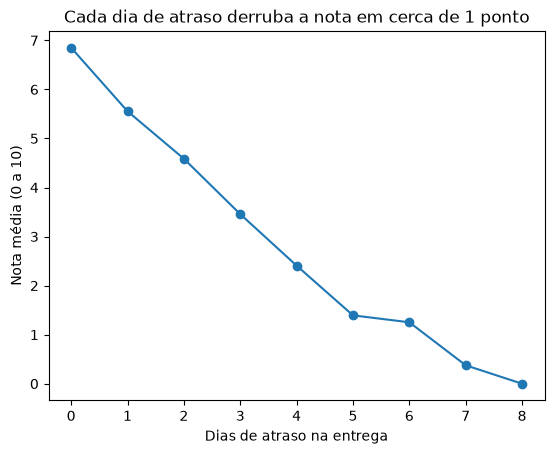

In [10]:
import matplotlib.pyplot as plt

media = df.groupby("delivery_delay_days")["nps_score"].mean()
ax = media.plot(marker="o")
ax.set_xlabel("Dias de atraso na entrega")
ax.set_ylabel("Nota média (0 a 10)")
ax.set_title("Cada dia de atraso derruba a nota em cerca de 1 ponto")   
plt.savefig("../reports/figuras/nps_por_atraso.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
fatores = ["delivery_delay_days", "complaints_count", "customer_service_contacts",
           "resolution_time_days", "delivery_time_days", "freight_value", "order_value"]

df.groupby("nps_class")[fatores].mean().round(2)

,delivery_delay_days,complaints_count,customer_service_contacts,resolution_time_days,delivery_time_days,freight_value,order_value
nps_class,,,,,,,
detrator,2.30,4.44,1.64,5.70,8.33,38.34,430.38
neutro,1.04,2.72,1.02,4.64,8.27,38.26,468.06
promotor,0.72,2.28,0.68,3.73,7.83,36.98,475.51


In [12]:
df.groupby("complaints_count")["nps_score"].agg(["mean", "count"])

,mean,count
complaints_count,,
0,8.517391,23
1,7.776923,117
2,6.114015,264
3,5.049789,474
4,4.330769,559
5,3.748921,417
6,3.162348,247
7,2.861006,159
8,2.156897,58


In [13]:
df.groupby("complaints_count")["nps_score"].agg(["mean", "count"])
(df["nps_class"] == "detrator").groupby(df["complaints_count"]).mean() * 100

complaints_count
0      17.391304
1      29.914530
2      65.151515
3      80.801688
4      89.087657
5      94.244604
6      97.165992
7      96.855346
8     100.000000
9     100.000000
10     90.909091
11    100.000000
Name: nps_class, dtype: float64

In [14]:
df.groupby("customer_service_contacts")["nps_score"].agg(["mean", "count"])

,mean,count
customer_service_contacts,,
0,5.631346,520
1,4.790539,761
2,4.215271,609
3,3.323793,290
4,2.706452,124
5,2.337500,32
6,0.742857,7
7,1.200000,3


In [15]:
df.groupby("customer_service_contacts")["nps_score"].agg(["mean", "count"])
(df["nps_class"] == "detrator").groupby(df["customer_service_contacts"]).mean() * 100

customer_service_contacts
0     69.807692
1     83.311432
2     88.013136
3     92.758621
4     97.580645
5     96.875000
6    100.000000
7    100.000000
Name: nps_class, dtype: float64

O atraso é o fator mais relacionado à queda do NPS, porém não há ponto claro de ruptura, pois, assim como o contato com atendimento, segue uma perda contínua e sem degrau. Como essa perda é proporcional, reduzir o atraso em geral já melhora o NPS, com prazos mais realistas e melhores transportadoras. O fator acionável é a reclamação do cliente, que tem o ponto de ruptura de 1 para 2 reclamações. Sendo assim, a janela de intervenção é resolver o problema do cliente na primeira reclamação, evitando a maior parte do dano, já que a partir da segunda, a maioria vira detrator. 

In [16]:
# NPS por região: nota média e % de detratores
df.groupby("customer_region")["nps_score"].agg(["mean", "count"]).round(2)
(df["nps_class"] == "detrator").groupby(df["customer_region"]).mean() * 100

# NPS por faixa de idade 
faixa_idade = pd.cut(df["customer_age"], bins=[17, 30, 45, 60, 69])
df.groupby(faixa_idade, observed=True)["nps_score"].agg(["mean", "count"]).round(2)

,mean,count
customer_age,,
"(17, 30]",4.63,570
"(30, 45]",4.36,710
"(45, 60]",4.39,671
"(60, 69]",4.66,395


In [17]:
def nps(notas):
    return ((notas >= 9).mean() - (notas < 7).mean()) * 100

df.groupby("customer_region")["nps_score"].agg(nota_media="mean", NPS=nps, pedidos="count").round(2)

,nota_media,NPS,pedidos
customer_region,,,
Centro-Oeste,4.28,-78.36,439
Nordeste,4.54,-80.35,453
Norte,4.50,-80.80,474
Sudeste,4.48,-78.34,494
Sul,4.60,-77.78,486


Nem a região nem a idade segmentam o NPS. Isso aponta que o problema é do processo (entrega e atendimento) e não de um público ou de uma praça específica, entáo o esforço deve ir para processos que atingem todos os clientes.

In [18]:
faixa_atraso = pd.cut(df["delivery_delay_days"], bins=[-1, 0, 2, 8], labels=["0", "1-2", "3+"])
faixa_recl   = pd.cut(df["complaints_count"], bins=[-1, 1, 3, 11], labels=["0-1", "2-3", "4+"])
df.pivot_table(values="nps_score", index=faixa_recl, columns=faixa_atraso, aggfunc="mean", observed=True).round(2)

delivery_delay_days,0,1-2,3+
complaints_count,,,
0-1,8.15,7.81,6.89
2-3,7.06,6.05,3.70
4+,5.68,4.37,2.41


In [19]:
faixa_atraso = pd.cut(df["delivery_delay_days"], bins=[-1, 0, 2, 8], labels=["0", "1-2", "3+"])
faixa_recl   = pd.cut(df["complaints_count"], bins=[-1, 1, 3, 11], labels=["0-1", "2-3", "4+"])
df.pivot_table(values="nps_score", index=faixa_recl, columns=faixa_atraso, aggfunc="count", observed=True).round(2)

delivery_delay_days,0,1-2,3+
complaints_count,,,
0-1,73,54,13
2-3,100,400,238
4+,99,791,578


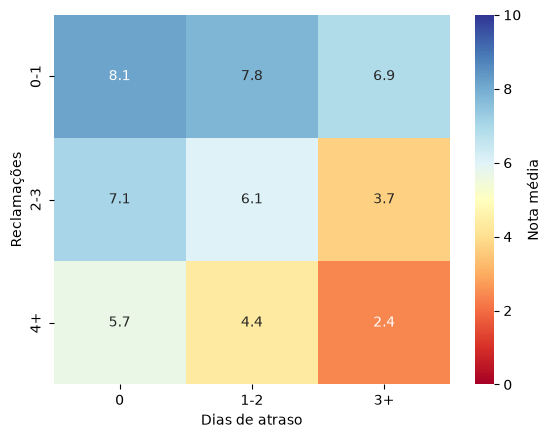

In [20]:
import seaborn as sns
tab = df.pivot_table(values="nps_score", index=faixa_recl, columns=faixa_atraso, aggfunc="mean", observed=True)
ax = sns.heatmap(tab, annot=True, fmt=".1f", cmap="RdYlBu", vmin=0, vmax=10, cbar_kws={"label": "Nota média"})
ax.set_xlabel("Dias de atraso"); ax.set_ylabel("Reclamações")
plt.savefig("../reports/figuras/nps_reclamacoes_x_atraso.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusões da EDA

- **Atraso na entrega** é o fator que mais pesa na nota (Spearman −0,57): perda contínua de cerca de 1 ponto por dia, e 88% dos pedidos chegam atrasados.
- **Reclamações** vêm em seguida (−0,50), com degrau da 1ª para a 2ª reclamação: janela de intervenção na primeira (hipótese a validar com A/B).
- **Atraso e reclamações são alavancas quase independentes** (correlação 0,19): exigem ações separadas, e os efeitos se somam.
- **Valor, frete, desconto, parcelas, região e idade** não segmentam o NPS.
- Correlação não é causalidade: os dados são de um único momento.